# Opponent scouting: verify the denominators

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '01_opponent_scouting'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
d = pd.read_csv(root / 'data/team_games.csv.gz')
profiles = pd.read_csv(root / 'results/team_profiles.csv')
assert d.game_id.nunique() == 1212
pooled = d.groupby('team')[['oreb', 'opp_dreb', 'fga', 'fgm', 'fg3m', 'fta', 'tov']].sum()
pooled['oreb_rate'] = pooled.oreb / (pooled.oreb + pooled.opp_dreb)
pooled['efg'] = (pooled.fgm + 0.5 * pooled.fg3m) / pooled.fga
published = profiles.loc[profiles.side.eq('Offense')].set_index('team')
assert np.allclose(pooled.oreb_rate, published.loc[pooled.index, 'oreb_rate'])
assert np.allclose(pooled.efg, published.loc[pooled.index, 'efg'])
display(pooled.loc[['OKC', 'DEN', 'HOU']])

,oreb,opp_dreb,fga,fgm,fg3m,fta,tov,oreb_rate,efg
team,,,,,,,,,
OKC,786,2732,7307,3534,1135,1905,1031,0.223422,0.561311
DEN,784,2524,7018,3480,1131,2064,1031,0.237001,0.576446
HOU,1201,2243,7177,3444,923,1875,1236,0.348722,0.544169


## Inspect the estimates

In [3]:
display(profiles.loc[profiles.team.isin(['OKC', 'DEN', 'HOU'])])

,team,seconds,points,fga,fgm,fg3m,fta,tov,oreb,dreb,opp_dreb,games,efg,estimated_possessions,turnover_rate,oreb_rate,free_throw_rate,points_per_estimated_possession,estimated_pace48,side
7,DEN,233100,9756,7018,3480,1131,2064,1031,784,2732,2524,80,0.576446,8173.16,0.126145,0.237001,0.294101,1.193663,100.981127,Offense
10,HOU,233100,9242,7177,3444,923,1875,1236,1201,2649,2243,80,0.544169,8037.00,0.153789,0.348722,0.261251,1.149932,99.298842,Offense
20,OKC,238260,9760,7307,3534,1135,1905,1031,786,2832,2732,82,0.561311,8390.20,0.122881,0.223422,0.260709,1.163262,101.417678,Offense
37,DEN,233100,9339,7294,3412,1091,1850,944,905,2524,2732,80,0.542569,8147.00,0.115871,0.248831,0.253633,1.146312,100.657915,Defense
40,HOU,233100,8817,7050,3248,988,1766,1072,910,2243,2649,80,0.530780,7989.04,0.134184,0.255690,0.250496,1.103637,98.706286,Defense
50,OKC,238260,8846,7247,3170,1176,1798,1372,973,2732,2832,82,0.518559,8437.12,0.162615,0.255716,0.248103,1.048462,101.984830,Defense


## Figures

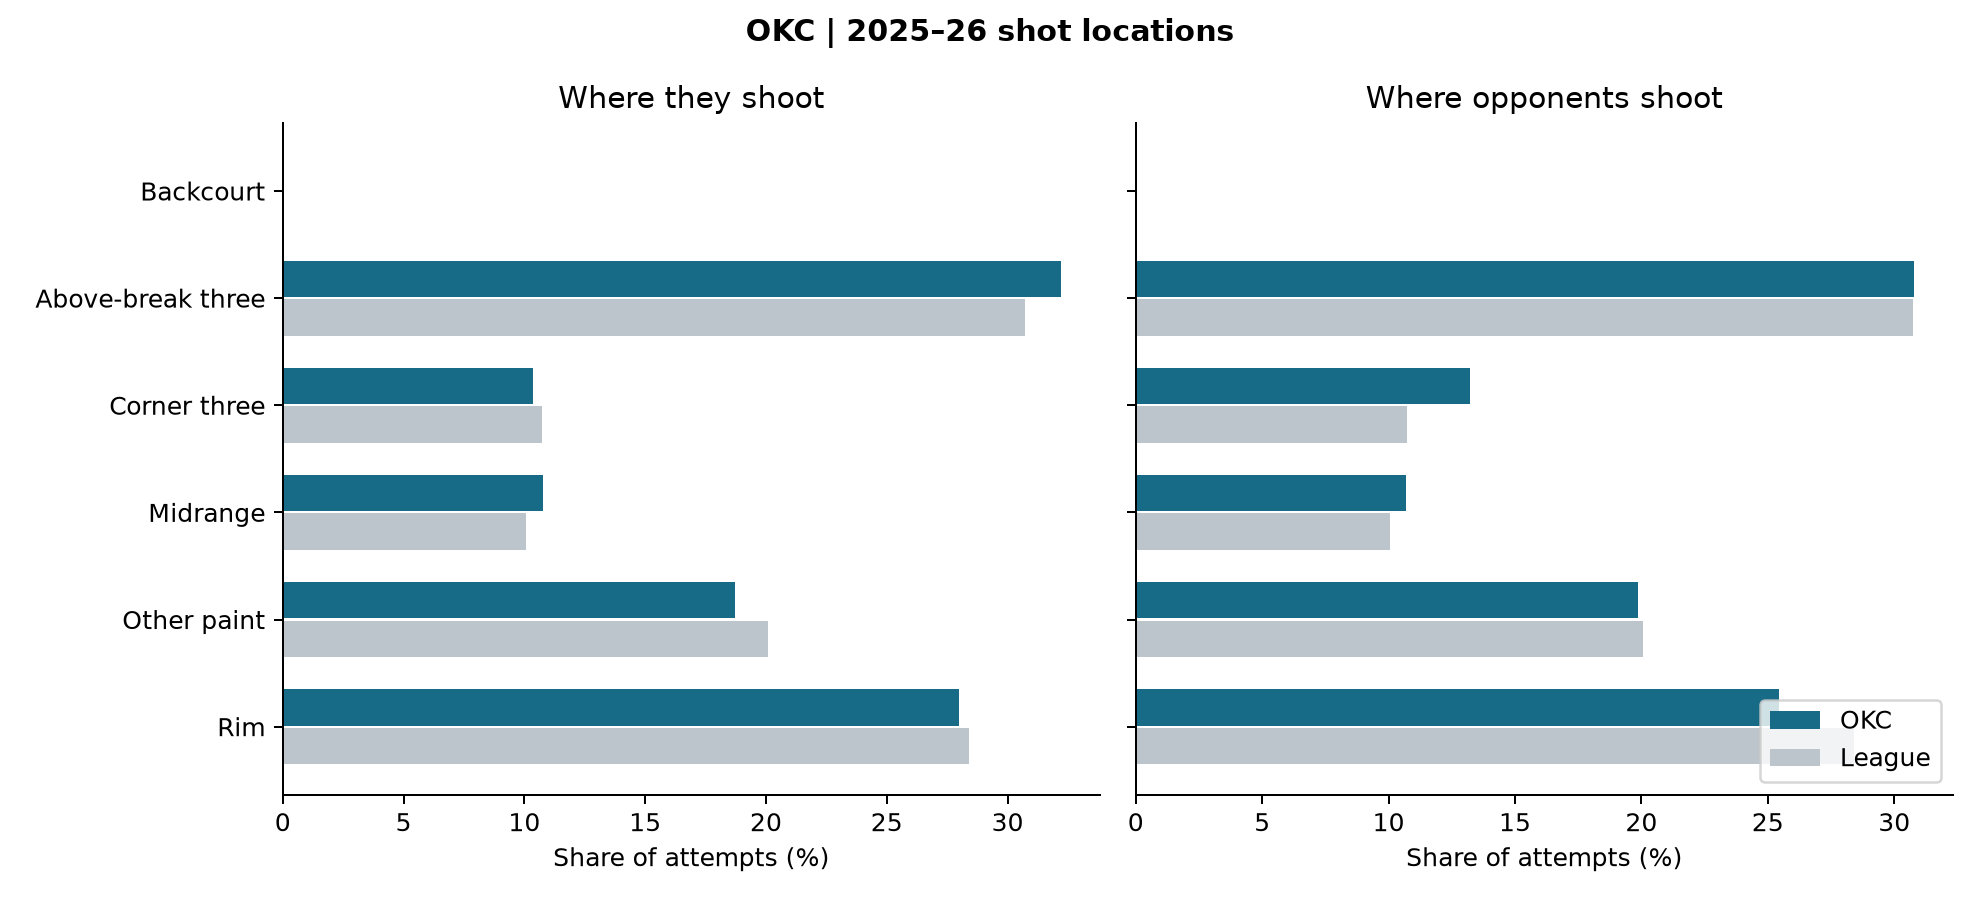

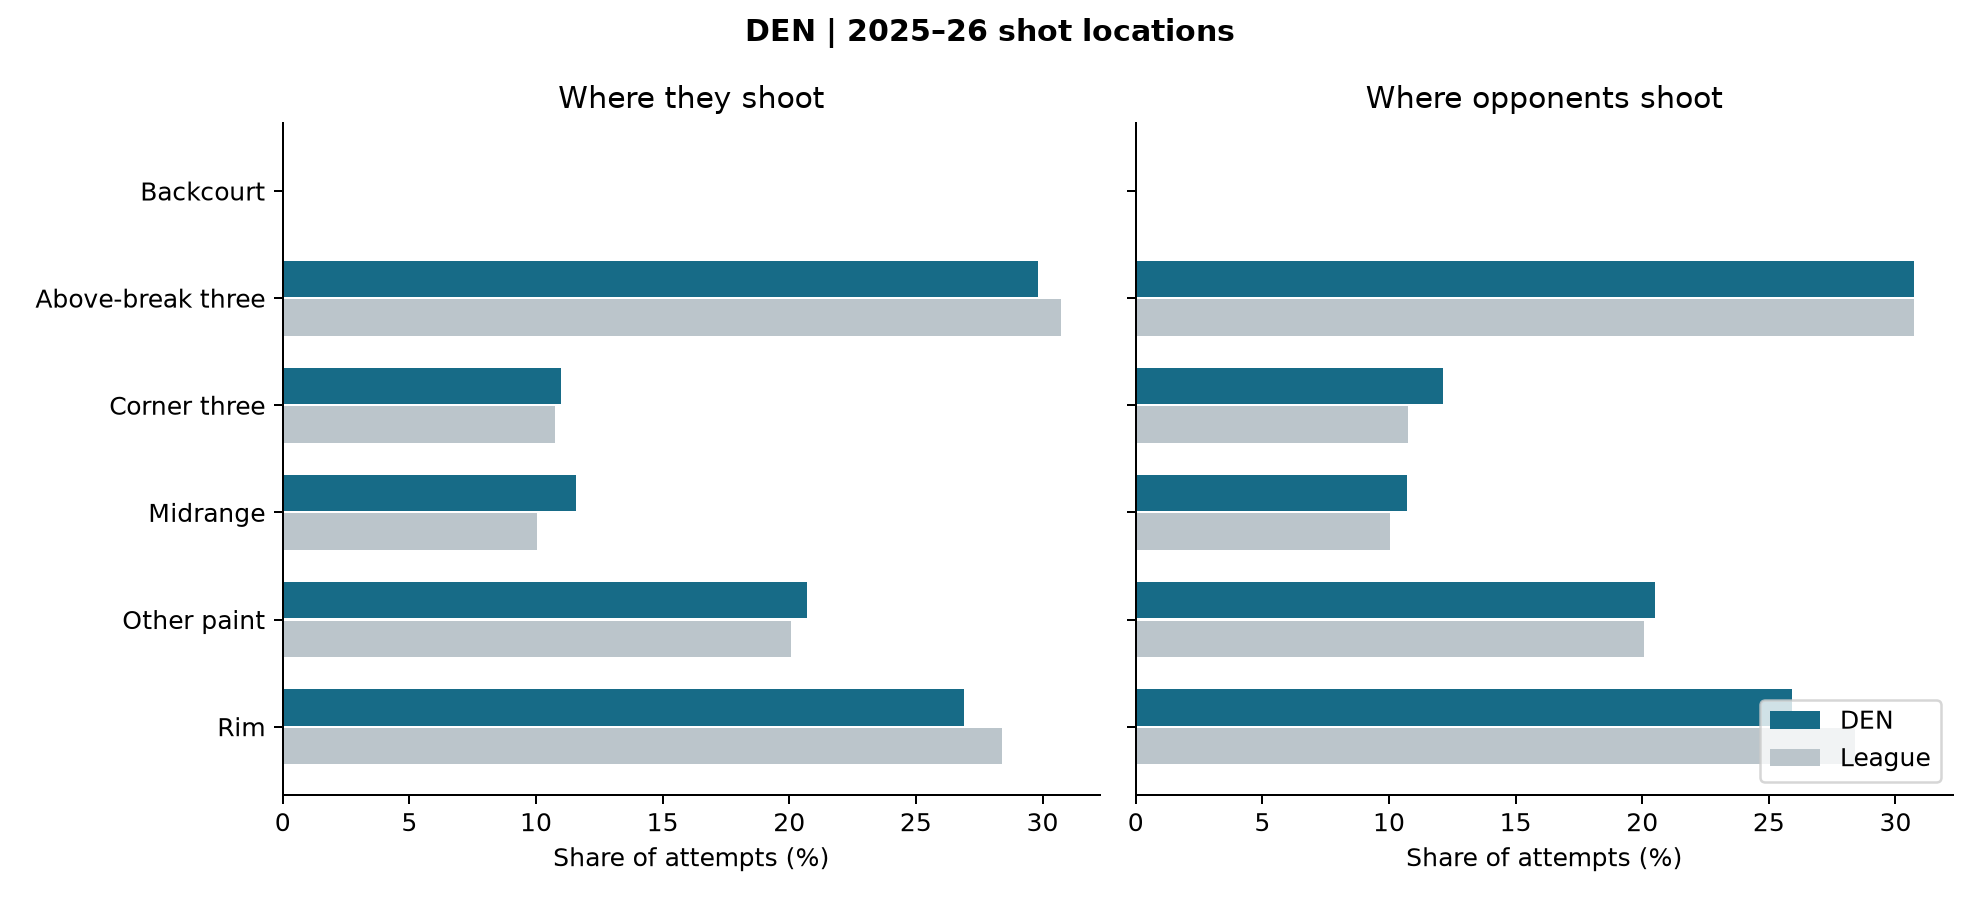

In [4]:
display(Image(filename=str(root / 'figures/OKC_shot_profile.png')))
display(Image(filename=str(root / 'figures/DEN_shot_profile.png')))

## Interpretation limits
Player rebounds exclude team rebounds. Possession rates are estimates; the sheets label their denominators. Location data do not show defensive positioning, and the written film questions are not completed film coding.